# Project 26 — Card-Fraud Triage: GMM Density Scoring vs Autoencoder Anomaly Detector

**Team T068 · Section B** — Sharma Piyush (2401010437) · Saransh Singh Tomar (2401010418) · Satwik Mani Tripathi (2401020056) · Gourav Tanwar (2401010173) · Alok Kumar (2401010058)
## Notebook 02 — Phase 1 (Machine Learning): Gaussian Mixture Density Scoring

**Idea.** Fit a probability density $p(\mathbf{x})$ to **legitimate** transactions only. A new transaction that the
legitimate density finds unlikely (low log-likelihood) is suspicious and goes to the review queue first.

**Anomaly score:** $\;s(\mathbf{x}) = -\log p(\mathbf{x})\;$ (higher = more suspicious).

### Theory recap
**Gaussian Mixture Model.** With $K$ components,
$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k\, \mathrm{N}(\mathbf{x}\mid \boldsymbol\mu_k, \boldsymbol\Sigma_k), \qquad \pi_k \ge 0,\; \sum_k \pi_k = 1,$$
$$\mathrm{N}(\mathbf{x}\mid\boldsymbol\mu,\boldsymbol\Sigma) = (2\pi)^{-d/2}|\boldsymbol\Sigma|^{-1/2}\exp\!\left(-\tfrac12(\mathbf{x}-\boldsymbol\mu)^\top\boldsymbol\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)\right).$$

**Expectation–Maximisation (Dempster, Laird & Rubin, 1977).** The log-likelihood
$\ell(\theta)=\sum_i \log \sum_k \pi_k \mathrm{N}(\mathbf{x}_i\mid\boldsymbol\mu_k,\boldsymbol\Sigma_k)$ has no closed-form
maximiser. EM alternates two steps, and each iteration never decreases $\ell$:
* **E-step** — responsibilities $\;\gamma_{ik} = \dfrac{\pi_k\,\mathrm{N}(\mathbf{x}_i\mid\boldsymbol\mu_k,\boldsymbol\Sigma_k)}{\sum_j \pi_j\,\mathrm{N}(\mathbf{x}_i\mid\boldsymbol\mu_j,\boldsymbol\Sigma_j)}$
* **M-step** — with $N_k=\sum_i\gamma_{ik}$: $\;\pi_k = N_k/N,\quad \boldsymbol\mu_k = \tfrac{1}{N_k}\sum_i \gamma_{ik}\mathbf{x}_i,\quad
  \boldsymbol\Sigma_k = \tfrac{1}{N_k}\sum_i \gamma_{ik}(\mathbf{x}_i-\boldsymbol\mu_k)(\mathbf{x}_i-\boldsymbol\mu_k)^\top + \lambda \mathbf{I}$

where $\lambda$ (`reg_covar`) keeps every $\boldsymbol\Sigma_k$ invertible. EM converges to a **local** optimum, so results
depend on initialisation (measured in §8).

**Choosing $K$ and the covariance type: information criteria.** With $p$ free parameters, maximised likelihood $\hat L$ and $n$ rows:
$$\text{AIC} = 2p - 2\log\hat L, \qquad \text{BIC} = p\log n - 2\log\hat L.$$
Both reward fit and penalise complexity. BIC's penalty grows with $\log n$, so it prefers smaller models. For $d$ features:

| covariance | free parameters $p$ |
|---|---|
| full | $(K-1) + Kd + K\,d(d+1)/2$ |
| diag | $(K-1) + Kd + Kd$ |

With $d=31$, each full-covariance component costs $31 + 496 = 527$ parameters. This is the root of the instability
the brief warns about in high dimensions.

## 0. Setup

In [1]:
# ============================================================
# Common setup — identical in every notebook of Project 26
# (data download, chronological split, features, metrics, plots)
# ============================================================
import os, sys, json, time, hashlib, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
IN_COLAB = "google.colab" in sys.modules

# ---------- paths ----------
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"  # public mirror of the ULB/Kaggle file
DATA_SHA256 = "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"
DATA_PATH = Path(os.environ.get("FRAUD_DATA", "creditcard.csv"))
OUT = Path(os.environ.get("FRAUD_OUT", "outputs"))
FIG, RES = OUT / "figures", OUT / "results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

# ---------- plotting ----------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
C_LEGIT, C_FRAUD = "#4C72B0", "#C44E52"


def savefig(name):
    """Save the current figure into outputs/figures (used by the IEEE report)."""
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")


def save_json(obj, name):
    def conv(o):
        if isinstance(o, dict):
            return {str(k): conv(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [conv(v) for v in o]
        if isinstance(o, np.generic):
            return o.item()
        return o
    (RES / name).write_text(json.dumps(conv(obj), indent=2))


# ---------- data ----------
def download_data(path=DATA_PATH):
    """Download the ULB credit-card dataset (once) and verify its checksum."""
    if not path.exists():
        print("Downloading dataset (~150 MB) ...")
        urllib.request.urlretrieve(DATA_URL, path)
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == DATA_SHA256, "checksum mismatch - the file is not the original dataset"
    return path


def load_data():
    """Read the CSV, drop exact duplicate rows, order by Time."""
    df = pd.read_csv(download_data())
    info = {"rows_raw": len(df), "frauds_raw": int(df.Class.sum())}
    dup = df.duplicated(keep="first")
    info.update(duplicates_dropped=int(dup.sum()), fraud_duplicates_dropped=int(df.loc[dup, "Class"].sum()))
    df = df.loc[~dup].sort_values("Time", kind="stable").reset_index(drop=True)
    info.update(rows=len(df), frauds=int(df.Class.sum()))
    return df, info


def chronological_split(df, fractions=(0.6, 0.2, 0.2)):
    """Consecutive time blocks: train (past) -> validation -> test (future)."""
    n = len(df)
    a, b = int(round(fractions[0] * n)), int(round((fractions[0] + fractions[1]) * n))
    return df.iloc[:a].copy(), df.iloc[a:b].copy(), df.iloc[b:].copy()


# ---------- features ----------
V_COLS = [f"V{i}" for i in range(1, 29)]
FEATURE_SETS = {
    "pca": V_COLS,
    "pca+amount": V_COLS + ["log_amount"],
    "full": V_COLS + ["log_amount", "hour_sin", "hour_cos"],
}


def add_features(df):
    """log(1+Amount) and time-of-day on the unit circle; raw Time is dropped."""
    out = df.copy()
    out["log_amount"] = np.log1p(out["Amount"])
    out["hour"] = (out["Time"] % 86400) / 3600.0
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    return out


def make_scaler(kind):
    return {
        "standard": StandardScaler(),
        "robust": RobustScaler(),
        "power": PowerTransformer(method="yeo-johnson", standardize=True),
        "quantile": QuantileTransformer(output_distribution="normal", n_quantiles=1000, subsample=200_000, random_state=SEED),
    }[kind]


class Preprocessor:
    """Select a feature set and scale it. Fitted on LEGITIMATE TRAINING rows only."""

    def __init__(self, feature_set="full", scaler="standard"):
        self.cols, self.kind = FEATURE_SETS[feature_set], scaler
        self.scaler = make_scaler(scaler)

    def fit(self, df_legit):
        assert df_legit["Class"].sum() == 0, "fit on legitimate rows only"
        self.scaler.fit(df_legit[self.cols])
        return self

    def transform(self, df):
        return self.scaler.transform(df[self.cols]).astype(np.float32)


# ---------- triage metrics (higher score = more suspicious) ----------
FPR_BUDGETS = (0.001, 0.005, 0.01)   # 0.1 %, 0.5 %, 1 % of legitimate customers wrongly flagged
CAPACITIES = (50, 100, 200, 500)       # alerts an analyst team can review


def pr_auc(y, s):
    return float(average_precision_score(y, s))


def threshold_at_fpr(y, s, fpr):
    """Smallest threshold whose false-positive rate on (y, s) is <= fpr."""
    neg = np.sort(np.asarray(s)[np.asarray(y) == 0])
    idx = min(max(int(np.ceil((1 - fpr) * len(neg))) - 1, 0), len(neg) - 1)
    return float(neg[idx])


def confusion_at(y, s, thr):
    y, flag = np.asarray(y), np.asarray(s) > thr
    tp, fp = int((flag & (y == 1)).sum()), int((flag & (y == 0)).sum())
    fn, tn = int((~flag & (y == 1)).sum()), int((~flag & (y == 0)).sum())
    return dict(threshold=float(thr), alerts=tp + fp, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), fpr=fp / max(fp + tn, 1))


def at_capacity(y, s, k):
    top = np.argsort(-np.asarray(s), kind="stable")[:k]
    tp = int(np.asarray(y)[top].sum())
    return dict(k=k, tp=tp, precision=tp / k, recall=tp / max(int(np.sum(y)), 1))


def bootstrap_ci(y, s, n_boot=1000, seed=SEED):
    """Stratified bootstrap 95 % interval for PR-AUC."""
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    vals = [pr_auc(y[i], s[i]) for i in
            (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot))]
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def paired_bootstrap(y, s_a, s_b, n_boot=1000, seed=SEED):
    """PR-AUC(a) - PR-AUC(b) on identical resamples -> difference, 95 % CI, P(a <= b)."""
    rng = np.random.default_rng(seed)
    y, s_a, s_b = map(np.asarray, (y, s_a, s_b))
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    d = []
    for _ in range(n_boot):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        d.append(pr_auc(y[i], s_a[i]) - pr_auc(y[i], s_b[i]))
    d = np.asarray(d)
    return dict(diff=pr_auc(y, s_a) - pr_auc(y, s_b), ci=[float(np.quantile(d, .025)), float(np.quantile(d, .975))],
                p_not_better=float((d <= 0).mean()))


def evaluate(name, y_val, s_val, y_test, s_test, n_boot=1000):
    """Thresholds are chosen on VALIDATION, then applied unchanged to TEST."""
    r = dict(model=name, val_pr_auc=pr_auc(y_val, s_val), test_pr_auc=pr_auc(y_test, s_test),
             test_roc_auc=float(roc_auc_score(y_test, s_test)), test_pr_auc_ci=bootstrap_ci(y_test, s_test, n_boot),
             base_rate=float(np.mean(y_test)), budgets={}, capacity={})
    for f in FPR_BUDGETS:
        r["budgets"][f] = confusion_at(y_test, s_test, threshold_at_fpr(y_val, s_val, f))
    for k in CAPACITIES:
        r["capacity"][k] = at_capacity(y_test, s_test, k)
    return r


def summary_table(reports):
    rows = []
    for r in reports:
        row = {"model": r["model"], "val PR-AUC": r["val_pr_auc"], "test PR-AUC": r["test_pr_auc"],
               "95% CI": "[{:.3f}, {:.3f}]".format(*r["test_pr_auc_ci"]), "test ROC-AUC": r["test_roc_auc"]}
        for f, b in r["budgets"].items():
            row[f"Recall@FPR{float(f)*100:g}%"] = b["recall"]
            row[f"real FPR{float(f)*100:g}%"] = b["fpr"]
        for k, c in r["capacity"].items():
            row[f"P@{k}"] = c["precision"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


def plot_pr_curves(y, scores, title, name=None, ax=None):
    """Precision-recall curves for several scorers on the same labels."""
    ax = ax or plt.subplots(figsize=(6.5, 4.8))[1]
    for label, s in scores.items():
        p, r, _ = precision_recall_curve(y, s)
        ax.plot(r, p, lw=1.8, label=f"{label} (AP={pr_auc(y, s):.3f})")
    ax.axhline(np.mean(y), ls="--", c="grey", lw=1, label=f"base rate = {np.mean(y):.4f}")
    ax.set(xlabel="Recall", ylabel="Precision", title=title, xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc="upper right")
    if name:
        savefig(name)
    return ax


def finish_colab(zip_name):
    """On Colab: zip outputs/ and download it so figures/results can go into the repo."""
    if IN_COLAB:
        import shutil
        from google.colab import files
        shutil.make_archive(zip_name, "zip", OUT)
        files.download(f"{zip_name}.zip")
    else:
        print("Outputs saved in", OUT.resolve())
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from scipy.stats import spearmanr


def n_params(k, d, cov):
    return (k - 1) + k * d + {"full": k * d * (d + 1) // 2, "diag": k * d}[cov]


def fit_gmm(X, k, cov="full", seed=SEED, reg_covar=1e-4, n_init=1):
    return GaussianMixture(n_components=k, covariance_type=cov, reg_covar=reg_covar, max_iter=500, n_init=n_init,
                           init_params="k-means++", random_state=seed).fit(X)


def gmm_score(g, X):
    """Anomaly score = negative log-likelihood under the legitimate density."""
    return -g.score_samples(X)

## 1. Data, split and inputs
Same protocol as Notebook 01: duplicates dropped, chronological 60/20/20 split, models fitted on **legitimate train
rows only**. For model selection we also hold out a random 10 % of the legitimate train rows. This lets us measure
held-out log-likelihood **without using any fraud label**.

**Seeds matter.** EM starts from a random (k-means++) initialisation and stops at a *local* optimum. A single run can
be lucky or unlucky (§8 measures this). Every comparison below therefore uses the **mean over 3 seeds**, never a single fit.

**Development subsample.** The selection studies (§2, §3, §8) fit about 100 GMMs. To keep the notebook within a
Colab session, they fit on a random **40,000-row subsample** of the legitimate training rows. The scalers are still
fitted on all legitimate rows. The **final model and all baselines (§4–§5) use all legitimate training rows.**

In [2]:
df, info = load_data()
train, val, test = chronological_split(df)
train, val, test = add_features(train), add_features(val), add_features(test)
train_legit = train[train.Class == 0]
y_val, y_test = val.Class.values, test.Class.values

rng = np.random.default_rng(SEED)
hold = rng.random(len(train_legit)) < 0.10
fit_rows, hold_rows = train_legit[~hold], train_legit[hold]
dev_rows = fit_rows.sample(40_000, random_state=SEED)          # development subsample for selection studies
print(f"legit train {len(train_legit):,} (fit {len(fit_rows):,} + label-free holdout {len(hold_rows):,}; dev subsample {len(dev_rows):,}) | "
      f"val {len(val):,} ({y_val.sum()} fraud) | test {len(test):,} ({y_test.sum()} fraud)")
SEEDS = [0, 1, 2]

legit train 169,894 (fit 153,021 + label-free holdout 16,873; dev subsample 40,000) | val 56,745 (57 fraud) | test 56,745 (74 fraud)


## 2. Feature-engineering ablation
Same GMM (full covariance, $K=4$), different inputs: **3 feature sets × 4 scalers**, each scaler fitted on legitimate
training rows only. The scalers are:
* *standard*: $(x-\mu)/\sigma$
* *robust*: (x − median)/IQR
* *power*: Yeo-Johnson, which reduces skew
* *quantile*: maps each feature's empirical CDF onto a standard normal, so every **marginal** becomes exactly
  Gaussian on the training data

The comparison uses **validation** PR-AUC (mean ± std over 3 seeds); test is not looked at.

pca         standard  val AP = 0.296 ± 0.290
pca         robust    val AP = 0.578 ± 0.168
pca         power     val AP = 0.085 ± 0.010
pca         quantile  val AP = 0.698 ± 0.009
pca+amount  standard  val AP = 0.246 ± 0.133
pca+amount  robust    val AP = 0.165 ± 0.121
pca+amount  power     val AP = 0.453 ± 0.114
pca+amount  quantile  val AP = 0.659 ± 0.021
full        standard  val AP = 0.507 ± 0.291
full        robust    val AP = 0.468 ± 0.212
full        power     val AP = 0.096 ± 0.024
full        quantile  val AP = 0.631 ± 0.086


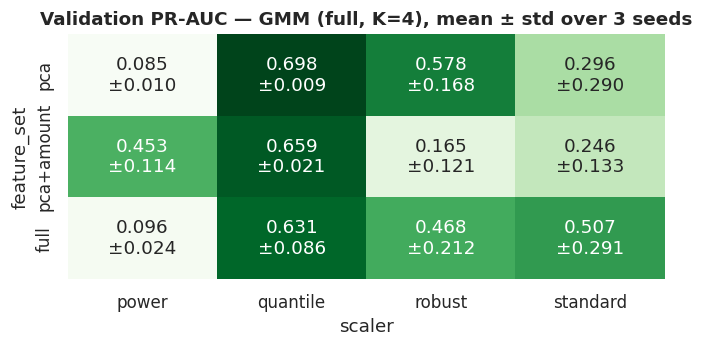

selected inputs: pca + quantile


In [3]:
abl = []
for fs in FEATURE_SETS:
    for sc in ["standard", "robust", "power", "quantile"]:
        p = Preprocessor(fs, sc).fit(train_legit)
        Xa, Xva = p.transform(dev_rows), p.transform(val)
        aps = [pr_auc(y_val, gmm_score(fit_gmm(Xa, 4, "full", seed=s), Xva)) for s in SEEDS]
        abl.append(dict(feature_set=fs, scaler=sc, d=len(p.cols), val_ap_mean=np.mean(aps), val_ap_std=np.std(aps)))
        print(f"{fs:<11s} {sc:<9s} val AP = {np.mean(aps):.3f} ± {np.std(aps):.3f}")
abl = pd.DataFrame(abl)
mean_ = abl.pivot(index="feature_set", columns="scaler", values="val_ap_mean").loc[list(FEATURE_SETS)]
std_ = abl.pivot(index="feature_set", columns="scaler", values="val_ap_std").loc[list(FEATURE_SETS)]
fig, ax = plt.subplots(figsize=(7, 2.9))
sns.heatmap(mean_, annot=mean_.map(lambda v: f"{v:.3f}") + "\n±" + std_.map(lambda v: f"{v:.3f}"), fmt="", cmap="Greens", ax=ax, cbar=False)
ax.set_title("Validation PR-AUC — GMM (full, K=4), mean ± std over 3 seeds")
savefig("02_feature_ablation"); plt.show()

best_fe = abl.loc[abl.val_ap_mean.idxmax()]
FS, SC = best_fe.feature_set, best_fe.scaler
print("selected inputs:", FS, "+", SC)

**What the ablation shows.**
* **Quantile scaling is the best scaler for every feature set.** It is also the only one whose result barely depends
  on the EM seed (± ≈ 0.01–0.09). With standard, robust or power scaling, the *same* configuration swings by ± 0.1–0.3
  from seed to seed.
* **Why.** Legitimate features are extremely heavy-tailed (Notebook 01: excess kurtosis up to ≈ 966). After
  standard, robust or power scaling, a few extreme *legitimate* values still dominate the covariance estimates, and
  each EM run locks onto different extreme points. The quantile transform makes every marginal exactly Gaussian on the
  training data, which brings the data much closer to what a GMM assumes.
* **Feature sets.** With 57 validation frauds, the differences between the three feature sets *under quantile
  scaling* are within the noise level. The numerically best cell is selected; the decision that matters is the
  scaler.

## 3. Choosing $K$ and the covariance type with AIC / BIC
On the selected inputs (development subsample) we sweep $K \in \{1,2,3,4,6,8,12,16,24\}$ for full and diagonal covariances. For each fit we
record AIC, BIC, and the average log-likelihood on the label-free holdout. **For analysis only**, we also record
validation PR-AUC (3 seeds for full covariance). This shows whether the unsupervised criteria pick a model that also
*detects fraud* well.

In [4]:
pre = Preprocessor(FS, SC).fit(train_legit)
X_fit, X_hold, X_val = pre.transform(dev_rows), pre.transform(hold_rows), pre.transform(val)
KS = [1, 2, 3, 4, 6, 8, 12, 16, 24]
rows = []
for cov in ["full", "diag"]:
    for k in KS:
        for s in (SEEDS if cov == "full" else [0]):
            t0 = time.time()
            g = fit_gmm(X_fit, k, cov, seed=s)
            row = dict(cov=cov, k=k, seed=s, n_params=n_params(k, X_fit.shape[1], cov), val_pr_auc=pr_auc(y_val, gmm_score(g, X_val)),
                       converged=g.converged_, fit_s=round(time.time() - t0, 1))
            if s == 0:
                row.update(aic=g.aic(X_fit), bic=g.bic(X_fit), holdout_ll=g.score(X_hold))
            rows.append(row)
        print(f"{cov:4s} K={k:2d}  BIC={rows[-len(SEEDS) if cov=='full' else -1]['bic']:.4e}  "
              f"val AP={np.mean([r['val_pr_auc'] for r in rows if r['cov']==cov and r['k']==k]):.3f}")
runs = pd.DataFrame(rows)
sweep = (runs.groupby(["cov", "k"])
             .agg(n_params=("n_params", "first"), aic=("aic", "first"), bic=("bic", "first"), holdout_ll=("holdout_ll", "first"),
                  val_ap_mean=("val_pr_auc", "mean"), val_ap_std=("val_pr_auc", "std"), fit_s=("fit_s", "mean"))
             .reset_index())

full K= 1  BIC=2.9951e+06  val AP=0.691
full K= 2  BIC=2.2182e+06  val AP=0.691
full K= 3  BIC=1.9706e+06  val AP=0.683
full K= 4  BIC=1.7951e+06  val AP=0.698
full K= 6  BIC=1.4865e+06  val AP=0.510
full K= 8  BIC=1.2506e+06  val AP=0.596
full K=12  BIC=1.0254e+06  val AP=0.591
full K=16  BIC=8.1912e+05  val AP=0.591
full K=24  BIC=6.7837e+05  val AP=0.554
diag K= 1  BIC=3.1755e+06  val AP=0.041
diag K= 2  BIC=3.1237e+06  val AP=0.043
diag K= 3  BIC=3.0128e+06  val AP=0.052
diag K= 4  BIC=2.9613e+06  val AP=0.050
diag K= 6  BIC=2.8880e+06  val AP=0.052
diag K= 8  BIC=2.8461e+06  val AP=0.073
diag K=12  BIC=2.7570e+06  val AP=0.064
diag K=16  BIC=2.6553e+06  val AP=0.071
diag K=24  BIC=2.5756e+06  val AP=0.108


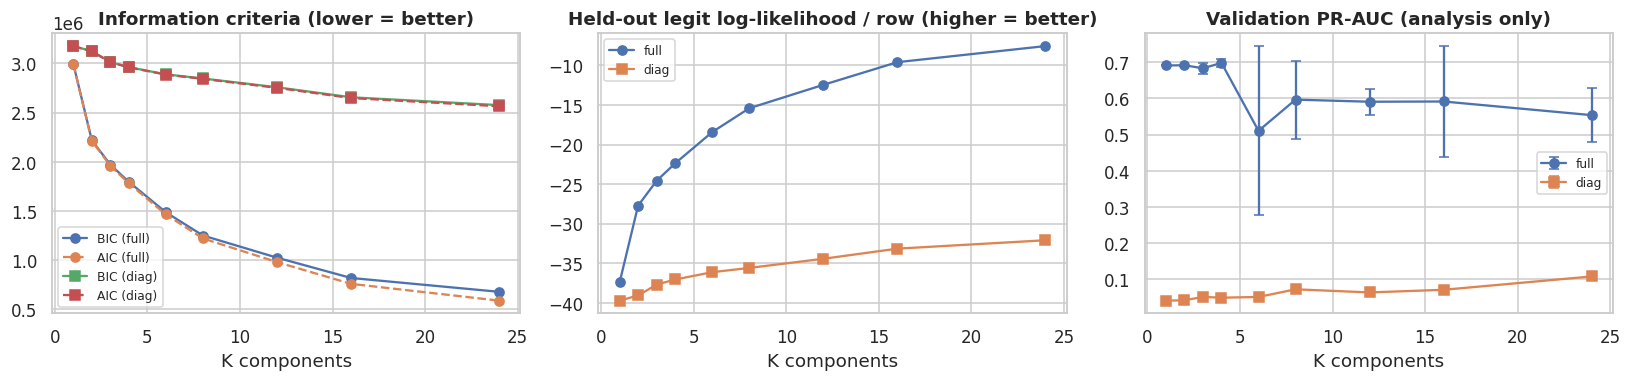

BIC choice: full, K=24 | AIC choice: K=24 | best mean validation PR-AUC: full, K=4


,cov,k,n_params,aic,bic,holdout_ll,val_ap_mean,val_ap_std,fit_s
0,diag,1,56,3175023.709,3175505.120,-39.729,0.041,NaN,0.100
1,diag,2,113,3122748.134,3123719.554,-39.071,0.043,NaN,0.800
2,diag,3,170,3011355.996,3012817.424,-37.700,0.052,NaN,1.000
3,diag,4,227,2959347.944,2961299.380,-37.056,0.050,NaN,1.400
4,diag,6,341,2885108.505,2888039.957,-36.133,0.052,NaN,1.100
5,diag,8,455,2842233.793,2846145.262,-35.595,0.073,NaN,1.600
6,diag,12,683,2751105.405,2756976.906,-34.439,0.064,NaN,5.600
7,diag,16,911,2647423.953,2655255.487,-33.159,0.071,NaN,4.500
8,diag,24,1367,2563830.353,2575581.953,-32.099,0.108,NaN,9.500
9,full,1,434,2991323.238,2995054.178,-37.422,0.691,0.000,0.267


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for cov, mk in [("full", "o"), ("diag", "s")]:
    s = sweep[sweep["cov"] == cov]
    axes[0].plot(s.k, s.bic, marker=mk, label=f"BIC ({cov})")
    axes[0].plot(s.k, s.aic, marker=mk, ls="--", label=f"AIC ({cov})")
    axes[1].plot(s.k, s.holdout_ll, marker=mk, label=cov)
    axes[2].errorbar(s.k, s.val_ap_mean, yerr=s.val_ap_std.fillna(0), marker=mk, capsize=3, label=cov)
axes[0].set(title="Information criteria (lower = better)", xlabel="K components")
axes[1].set(title="Held-out legit log-likelihood / row (higher = better)", xlabel="K components")
axes[2].set(title="Validation PR-AUC (analysis only)", xlabel="K components")
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); savefig("02_gmm_model_selection"); plt.show()

full = sweep[sweep["cov"] == "full"].set_index("k")
K_BIC, K_AIC = int(sweep.loc[sweep.bic.idxmin(), "k"]), int(sweep.loc[sweep.aic.idxmin(), "k"])
COV_BIC = sweep.loc[sweep.bic.idxmin(), "cov"]
K_VAL = int(full.val_ap_mean.idxmax())
print(f"BIC choice: {COV_BIC}, K={K_BIC} | AIC choice: K={K_AIC} | best mean validation PR-AUC: full, K={K_VAL}")
sweep.round(3)

**Information criteria vs detection quality.**
* **AIC and BIC both choose the largest model tried,** and the label-free held-out log-likelihood also keeps
  improving with K. With tens of thousands of rows, the BIC penalty $p\log n$ is small next to the likelihood gained
  from describing the heavy tails ever more finely.
* **Validation PR-AUC does not follow.** It is flat or slightly lower for large K, and the seed-to-seed spread grows
  with K (more components means more local optima). Small mixtures (K ≤ 4) are as good as any, and the most stable.
* **Diagonal covariances are far worse at every K.** Fraud shows up in *combinations* of components (Notebook 01,
  §7), and a diagonal model cannot represent correlations.

**Decision.** Full covariance, **K chosen by mean validation PR-AUC** (the validation block exists for this purpose).
The BIC choice is kept as a baseline in §5, refit on all rows, to show what trusting the criterion would have given.

## 4. Final Phase-1 model
Full covariance, $K$ = the value with the best mean validation PR-AUC, on the selected inputs. It is refit on **all**
legitimate training rows with **5 EM restarts** (`n_init=5`). scikit-learn keeps the restart with the highest
likelihood, which is a label-free way to avoid a bad local optimum.

In [6]:
SEL_COV, SEL_K = "full", K_VAL
pre = Preprocessor(FS, SC).fit(train_legit)
Xtr, Xv, Xte = pre.transform(train_legit), pre.transform(val), pre.transform(test)
gmm = fit_gmm(Xtr, SEL_K, SEL_COV, n_init=5)
s_val_gmm, s_test_gmm = gmm_score(gmm, Xv), gmm_score(gmm, Xte)
print(f"Final GMM: cov={SEL_COV}, K={SEL_K}, inputs={FS}+{SC} | converged={gmm.converged_} | "
      f"weights={np.round(np.sort(gmm.weights_)[::-1], 3)}")

Final GMM: cov=full, K=4, inputs=pca+quantile | converged=True | weights=[0.32  0.263 0.241 0.175]


## 5. Reference baselines
These put the GMM's numbers in context. They are not alternatives to it.
* **GMM with the BIC-selected $K$**: what the pure information-criterion choice would have given.
* **Single Gaussian** ($K=1$): equivalent to ranking by Mahalanobis distance. Does the *mixture* help?
* **Single Gaussian on standard-scaled inputs**: isolates the effect of feature engineering.
* **Isolation Forest** (Liu et al., 2008): a non-density unsupervised detector, also fitted on legitimate rows only.
* **Supervised logistic regression**: *uses fraud labels* from the training block, so it is **not** a fair
  competitor. It is an upper reference that shows what label information is worth.

In [7]:
g_bic = fit_gmm(Xtr, K_BIC, COV_BIC)
g1 = fit_gmm(Xtr, 1, "full")
pre_std = Preprocessor(FS, "standard").fit(train_legit)
g1_std = fit_gmm(pre_std.transform(train_legit), 1, "full")
iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Xtr)
logreg = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.1).fit(pre.transform(train), train.Class.values)

scores = {
    f"GMM (K={SEL_K}, {SEL_COV})": (s_val_gmm, s_test_gmm),
    f"GMM, BIC choice (K={K_BIC}, {COV_BIC})": (gmm_score(g_bic, Xv), gmm_score(g_bic, Xte)),
    "Single Gaussian (K=1)": (gmm_score(g1, Xv), gmm_score(g1, Xte)),
    "Single Gaussian, standard scaling": (gmm_score(g1_std, pre_std.transform(val)), gmm_score(g1_std, pre_std.transform(test))),
    "Isolation Forest": (-iso.score_samples(Xv), -iso.score_samples(Xte)),
    "Supervised LogReg (uses labels)": (logreg.decision_function(Xv), logreg.decision_function(Xte)),
}
reports = [evaluate(name, y_val, sv, y_test, st) for name, (sv, st) in scores.items()]
table = summary_table(reports)
table.round(3)

,val PR-AUC,test PR-AUC,95% CI,test ROC-AUC,Recall@FPR0.1%,real FPR0.1%,Recall@FPR0.5%,real FPR0.5%,Recall@FPR1%,real FPR1%,P@50,P@100,P@200,P@500
model,,,,,,,,,,,,,,
"GMM (K=4, full)",0.695,0.686,"[0.572, 0.808]",0.934,0.757,0.001,0.784,0.003,0.784,0.006,0.90,0.56,0.285,0.116
"GMM, BIC choice (K=24, full)",0.634,0.626,"[0.512, 0.757]",0.955,0.662,0.000,0.757,0.003,0.770,0.007,0.86,0.53,0.280,0.114
Single Gaussian (K=1),0.686,0.691,"[0.581, 0.804]",0.963,0.757,0.001,0.757,0.003,0.770,0.006,0.92,0.56,0.280,0.114
"Single Gaussian, standard scaling",0.074,0.163,"[0.125, 0.222]",0.959,0.081,0.001,0.514,0.003,0.716,0.007,0.18,0.28,0.200,0.110
Isolation Forest,0.028,0.050,"[0.036, 0.072]",0.939,0.014,0.001,0.203,0.004,0.432,0.007,0.02,0.06,0.060,0.072
Supervised LogReg (uses labels),0.738,0.739,"[0.648, 0.827]",0.981,0.770,0.001,0.851,0.003,0.851,0.007,0.88,0.56,0.305,0.126


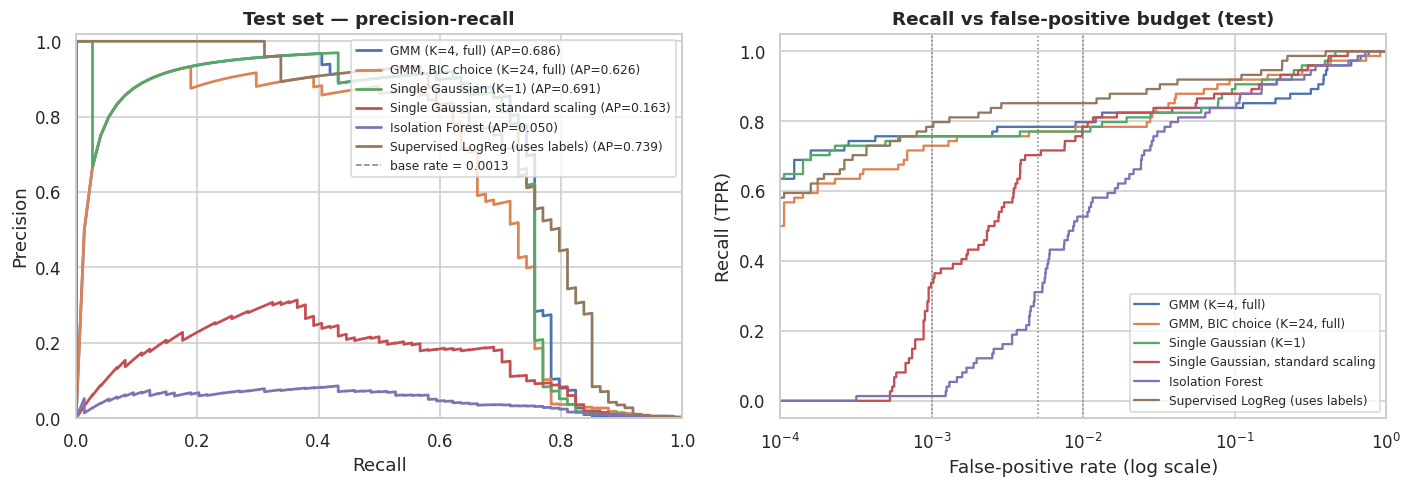

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
plot_pr_curves(y_test, {k: v[1] for k, v in scores.items()}, "Test set — precision-recall", ax=axes[0])
from sklearn.metrics import roc_curve
for name, (_, st) in scores.items():
    fpr, tpr, _ = roc_curve(y_test, st)
    axes[1].plot(fpr, tpr, label=name)
for f in FPR_BUDGETS:
    axes[1].axvline(f, color="grey", ls=":", lw=1)
axes[1].set(xscale="log", xlim=(1e-4, 1), xlabel="False-positive rate (log scale)", ylabel="Recall (TPR)",
            title="Recall vs false-positive budget (test)")
axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("02_pr_and_budget_curves"); plt.show()

**Reading the table** (test set, thresholds fixed on validation; 74 test frauds, so 95 % CIs are about ± 0.1 wide):
* **Selected GMM.** It catches about three quarters of test frauds while flagging under 0.1 % of legitimate customers
  (0.1 % budget), and its top-50 review queue is ≈ 90 % fraud.
* **The number of components hardly matters.** A **single Gaussian (K = 1)** on the same inputs scores 0.691 against
  0.686 for K = 4. The BIC-selected mixture (K = 24, refit on all rows) scores *lower* (0.626), though within the
  wide confidence intervals. (In a local re-run with a different numerical library the same K = 24 model scored 0.73:
  large mixtures are unstable.) Information criteria keep asking for more components without a measurable gain in
  detection.
* **The scaler matters enormously.** The same single Gaussian on standard-scaled inputs collapses (PR-AUC ≈ 0.16).
  **Feature engineering, not the mixture size, is the key design decision of Phase 1.**
* **Isolation Forest.** Weak at the top of the ranking. Its random axis-aligned splits cannot express the
  "unusual combination" structure of fraud.
* **Supervised logistic regression.** It *uses labels* and is an upper reference only. It is only slightly better,
  so the label-free GMM recovers most of what labels are worth.
* **ROC-AUC.** ≈ 0.93–0.98 for almost every model, including weak ones. That is why it is not our main metric.

## 6. Threshold analysis and false-positive trade-offs
A deployed system needs a **threshold**: alert if $s(\mathbf{x}) > t$. The threshold is chosen on validation, where
the rate of falsely flagged legitimate customers equals the budget. It is then frozen and applied to the test period.

In [9]:
op = []
for f in FPR_BUDGETS:
    b = reports[0]["budgets"][f]
    hours = (test.Time.max() - test.Time.min()) / 3600
    op.append({"FP budget (val)": f"{f:.1%}", "threshold": round(b["threshold"], 2), "alerts": b["alerts"],
               "alerts / hour": round(b["alerts"] / hours, 1), "frauds caught": f"{b['tp']} / {b['tp'] + b['fn']}",
               "recall": round(b["recall"], 3), "precision": round(b["precision"], 3),
               "realised test FPR": f"{b['fpr']:.3%}", "legit customers flagged": b["fp"]})
pd.DataFrame(op)

,FP budget (val),threshold,alerts,alerts / hour,frauds caught,recall,precision,realised test FPR,legit customers flagged
0,0.1%,89.65,94,12.3,56 / 74,0.757,0.596,0.067%,38
1,0.5%,68.95,221,28.9,58 / 74,0.784,0.262,0.288%,163
2,1.0%,62.51,399,52.1,58 / 74,0.784,0.145,0.602%,341


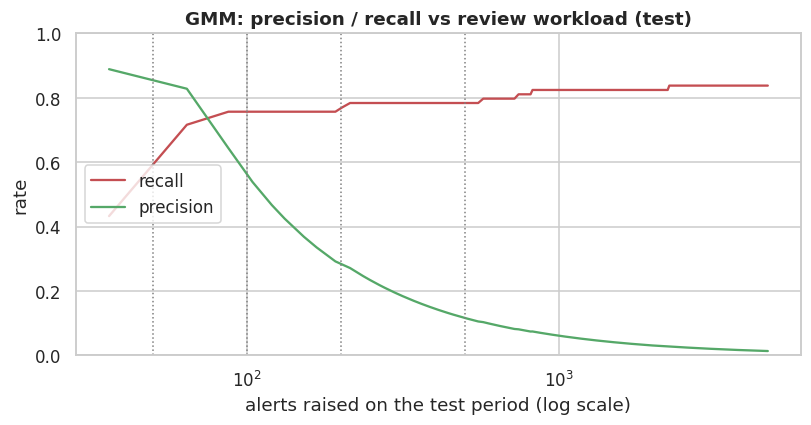

In [10]:
# How do precision, recall and workload move as the threshold slides? (test set, GMM)
qs = np.linspace(0.90, 0.9995, 200)
thr = np.quantile(s_val_gmm, qs)
curve = pd.DataFrame([confusion_at(y_test, s_test_gmm, t) for t in thr])
fig, ax1 = plt.subplots(figsize=(8.5, 3.8))
ax1.plot(curve.alerts, curve.recall, color=C_FRAUD, label="recall")
ax1.plot(curve.alerts, curve.precision, color="#55A868", label="precision")
ax1.set(xscale="log", xlabel="alerts raised on the test period (log scale)", ylabel="rate", ylim=(0, 1))
for k in CAPACITIES:
    ax1.axvline(k, color="grey", ls=":", lw=1)
ax1.legend(loc="center left"); ax1.set_title("GMM: precision / recall vs review workload (test)")
savefig("02_threshold_tradeoff"); plt.show()

**Reading the trade-off.** Moving the threshold down catches more fraud but floods analysts with false alarms. The
two quantities trade off monotonically:
* the **0.1 %** budget gives a small, high-precision queue (block or step-up authentication);
* the **1 %** budget catches more fraud but most alerts are false (cheap checks only, e.g. an SMS confirmation).

A simple **cost view** makes this concrete. Assume every alert costs a fixed review cost $c$ and every missed fraud
loses its transaction amount. The best threshold minimises *review cost + missed-fraud amount*.

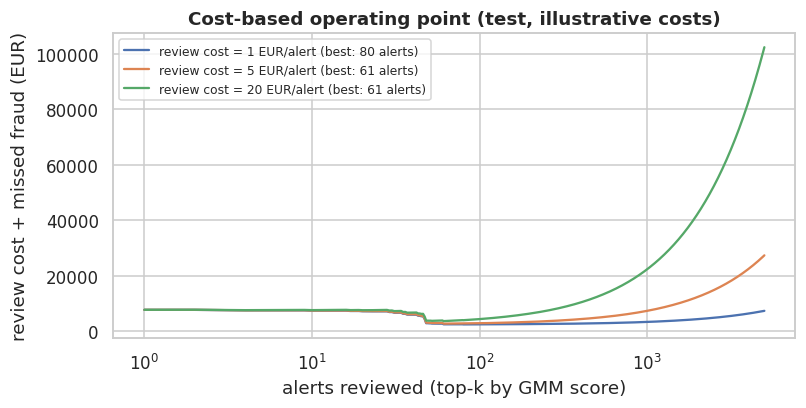

,review_cost,best_alerts,total_cost,no_model_cost
0,1,80,2482.0,7728.0
1,5,61,2763.0,7728.0
2,20,61,3678.0,7728.0


In [11]:
def cost_curve(y, s, amount, review_cost):
    order = np.argsort(-s)
    y_o, a_o = y[order], amount[order]
    caught_amount = np.cumsum(y_o * a_o)
    k = np.arange(1, len(s) + 1)
    total_fraud = (y * amount).sum()
    return k, review_cost * k + (total_fraud - caught_amount)

amt = test.Amount.values
fig, ax = plt.subplots(figsize=(8, 3.6))
cost_rows = []
for c in [1, 5, 20]:
    k, cost = cost_curve(y_test, s_test_gmm, amt, c)
    i = int(np.argmin(cost[:5000]))
    ax.plot(k[:5000], cost[:5000], label=f"review cost = {c} EUR/alert (best: {k[i]} alerts)")
    cost_rows.append(dict(review_cost=c, best_alerts=int(k[i]), total_cost=float(cost[i]), no_model_cost=float((y_test * amt).sum())))
ax.set(xscale="log", xlabel="alerts reviewed (top-k by GMM score)", ylabel="review cost + missed fraud (EUR)",
       title="Cost-based operating point (test, illustrative costs)")
ax.legend(fontsize=8); savefig("02_cost_curve"); plt.show()
pd.DataFrame(cost_rows).round(0)

## 7. Score distributions

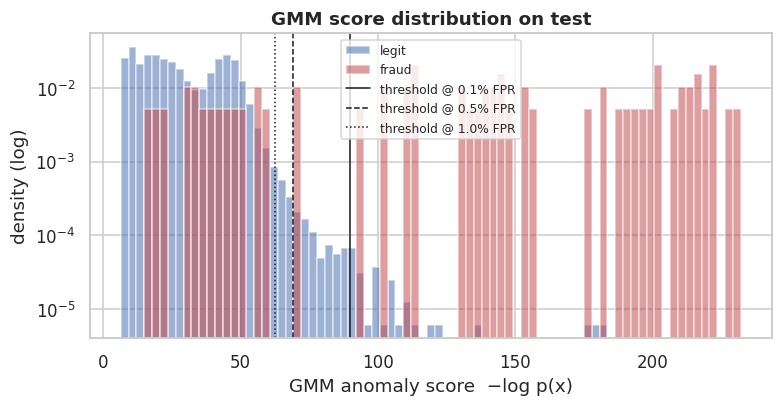

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(np.quantile(s_test_gmm, .001), np.quantile(s_test_gmm, .9999), 80)
ax.hist(s_test_gmm[y_test == 0], bins=bins, density=True, alpha=.55, color=C_LEGIT, label="legit")
ax.hist(s_test_gmm[y_test == 1], bins=bins, density=True, alpha=.55, color=C_FRAUD, label="fraud")
for f, ls in zip(FPR_BUDGETS, ["-", "--", ":"]):
    ax.axvline(reports[0]["budgets"][f]["threshold"], color="k", ls=ls, lw=1, label=f"threshold @ {f:.1%} FPR")
ax.set(yscale="log", xlabel="GMM anomaly score  −log p(x)", ylabel="density (log)", title="GMM score distribution on test")
ax.legend(fontsize=8); savefig("02_score_distribution"); plt.show()

## 8. Stability — the "high-dimensional instability" gap, measured
EM finds a local optimum, so we refit with 5 random seeds (one EM run each) and ask three questions:
1. How much does test PR-AUC move?
2. Do the seeds agree on the *ranking* of transactions (Spearman ρ)?
3. Do they send the *same* top-100 transactions to review?

We run this (on the development subsample) for the selected inputs **and** for plain standard scaling at several
$K$, to see where the instability comes from. We also inspect how close the fitted covariance matrices are to singular (condition number
$\kappa=\lambda_{max}/\lambda_{min}$).

quantile (selected)  K= 4  test AP 0.705 ± 0.032  [0.652, 0.737]  Spearman 0.897  top-100 overlap 0.87
standard             K= 4  test AP 0.505 ± 0.224  [0.148, 0.743]  Spearman 0.851  top-100 overlap 0.77
quantile (selected)  K= 8  test AP 0.650 ± 0.033  [0.592, 0.686]  Spearman 0.866  top-100 overlap 0.79
standard             K= 8  test AP 0.418 ± 0.226  [0.109, 0.685]  Spearman 0.798  top-100 overlap 0.63
quantile (selected)  K=16  test AP 0.604 ± 0.089  [0.492, 0.743]  Spearman 0.906  top-100 overlap 0.74
standard             K=16  test AP 0.511 ± 0.229  [0.104, 0.722]  Spearman 0.813  top-100 overlap 0.63


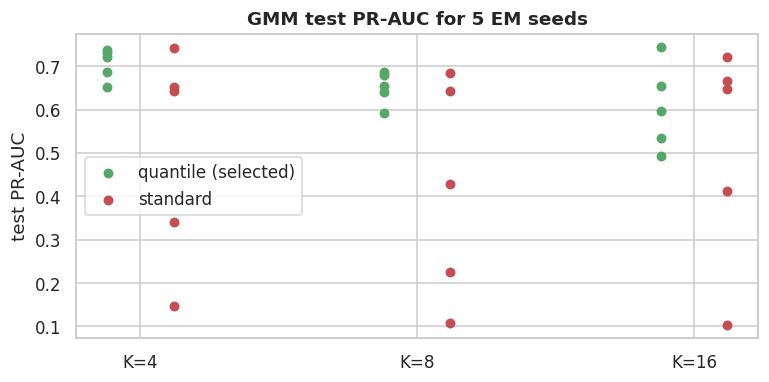

,inputs,k,ap_mean,ap_std,ap_min,ap_max,spearman,top100_overlap
0,quantile (selected),4,0.705,0.032,0.652,0.737,0.897,0.870
1,standard,4,0.505,0.224,0.148,0.743,0.851,0.769
2,quantile (selected),8,0.650,0.033,0.592,0.686,0.866,0.794
3,standard,8,0.418,0.226,0.109,0.685,0.798,0.633
4,quantile (selected),16,0.604,0.089,0.492,0.743,0.906,0.738
5,standard,16,0.511,0.229,0.104,0.722,0.813,0.629


In [13]:
def seed_study(Xa, Xt_, k, n_seeds=5):
    sc_ = np.array([gmm_score(fit_gmm(Xa, k, "full", seed=sd), Xt_) for sd in range(n_seeds)])
    ap = [pr_auc(y_test, x) for x in sc_]
    rho = [spearmanr(sc_[i], sc_[j]).statistic for i in range(n_seeds) for j in range(i + 1, n_seeds)]
    top = [set(np.argsort(-x)[:100]) for x in sc_]
    ov = [len(top[i] & top[j]) / 100 for i in range(n_seeds) for j in range(i + 1, n_seeds)]
    return dict(ap=ap, ap_mean=np.mean(ap), ap_std=np.std(ap), ap_min=np.min(ap), ap_max=np.max(ap),
                spearman=np.mean(rho), top100_overlap=np.mean(ov))

Xstd_dev, Xstd_te = pre_std.transform(dev_rows), pre_std.transform(test)
Xdev = pre.transform(dev_rows)
stab_rows = []
for k in sorted({4, 8, 16, SEL_K}):
    for name, (Xa, Xt_) in {f"{SC} (selected)": (Xdev, Xte), "standard": (Xstd_dev, Xstd_te)}.items():
        r = seed_study(Xa, Xt_, k)
        stab_rows.append(dict(inputs=name, k=k, **r))
        print(f"{name:<20s} K={k:2d}  test AP {r['ap_mean']:.3f} ± {r['ap_std']:.3f}  [{r['ap_min']:.3f}, {r['ap_max']:.3f}]  "
              f"Spearman {r['spearman']:.3f}  top-100 overlap {r['top100_overlap']:.2f}")
stab = pd.DataFrame(stab_rows)

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, r in stab.iterrows():
    x = list(sorted(stab.k.unique())).index(r.k) + (-0.12 if "selected" in r.inputs else 0.12)
    ax.scatter(np.full(len(r.ap), x), r.ap, color="#55A868" if "selected" in r.inputs else C_FRAUD, s=30,
               label=r.inputs if i < 2 else None)
ax.set_xticks(range(stab.k.nunique())); ax.set_xticklabels([f"K={k}" for k in sorted(stab.k.unique())])
ax.set(ylabel="test PR-AUC", title="GMM test PR-AUC for 5 EM seeds"); ax.legend()
savefig("02_seed_stability"); plt.show()
stab.drop(columns="ap").round(3)

In [14]:
eig = [np.linalg.eigvalsh(c) for c in gmm.covariances_]
cond = pd.DataFrame({"weight": gmm.weights_, "lambda_min": [e.min() for e in eig], "lambda_max": [e.max() for e in eig],
                     "condition_number": [e.max() / e.min() for e in eig]}).sort_values("weight", ascending=False)
cond.round(4)

,weight,lambda_min,lambda_max,condition_number
0,0.3204,0.0040,2.4414,611.0932
2,0.2633,0.0009,2.2523,2467.0583
3,0.2412,0.2461,3.3717,13.7028
1,0.1751,0.0031,3.8291,1252.4082


In [15]:
# Sensitivity to the covariance regulariser lambda (reg_covar)
reg_rows = []
for lam in [1e-6, 1e-4, 1e-2, 1e-1]:
    g = fit_gmm(Xtr, SEL_K, SEL_COV, reg_covar=lam)
    reg_rows.append(dict(reg_covar=lam, val_pr_auc=pr_auc(y_val, gmm_score(g, Xv)), converged=g.converged_))
pd.DataFrame(reg_rows).round(4)

,reg_covar,val_pr_auc,converged
0,0.0000,0.6818,True
1,0.0001,0.6816,True
2,0.0100,0.7037,True
3,0.1000,0.6720,True


**Stability findings.**
* **Standard scaling is fragile.** The *same* configuration (K = 4, standard scaling) gives test PR-AUC anywhere from
  0.15 to 0.74 depending only on the random initialisation of EM. With quantile inputs the range is 0.65–0.74.
* **Quantile inputs are much more stable,** but the spread still grows with K: more components means more local
  optima.
* **Covariances are near-singular.** The final model's covariance matrices have condition numbers in the hundreds
  to thousands, so some directions are almost flat. `reg_covar` keeps them invertible. Values from 0 to 1e-2 barely
  change validation PR-AUC; strong regularisation (0.1) blurs the density and hurts.

This is the brief's "instability in high dimensions", measured: every full-covariance component carries hundreds of
parameters, and EM's answer depends on where it starts.

## 9. Error analysis — what does the GMM miss, and whom does it wrongly flag?
Operating point: the 0.5 % false-positive budget, chosen on validation.

In [16]:
thr05 = reports[0]["budgets"][0.005]["threshold"]
t = test.assign(score=s_test_gmm, flagged=s_test_gmm > thr05)
groups = {"caught fraud (TP)": t[(t.Class == 1) & t.flagged], "missed fraud (FN)": t[(t.Class == 1) & ~t.flagged],
          "false alarm (FP)": t[(t.Class == 0) & t.flagged], "legit, not flagged (TN)": t[(t.Class == 0) & ~t.flagged]}
err = pd.DataFrame({g: {"count": len(x), "median amount": x.Amount.median(), "mean |V14|": x.V14.abs().mean(),
                        "mean |V17|": x.V17.abs().mean(), "mean score": x.score.mean()} for g, x in groups.items()}).T
err.round(2)

,count,median amount,mean |V14|,mean |V17|,mean score
caught fraud (TP),58.0,2.95,8.00,3.88,173.13
missed fraud (FN),16.0,7.80,2.09,1.41,38.62
false alarm (FP),163.0,145.52,2.58,1.97,84.28
"legit, not flagged (TN)",56508.0,18.00,0.65,0.57,28.14


Missed frauds look like ordinary transactions in V14/V17 (small absolute values) and sit in dense regions of the
legitimate density. No density threshold can catch them without flagging many legitimate customers. False alarms
are legitimate transactions in sparse regions (large amounts, unusual component values). They are "rare but
honest" behaviour, the classic weakness of any purely density-based detector.

## 10. Phase-1 conclusions and the gap that motivates Phase 2

**Results.**
1. **Feature engineering is the decisive design choice.** Mapping every feature to a Gaussian marginal (quantile
   transform, fitted on legitimate rows only) turns an unusable detector (PR-AUC ≈ 0.16) into a strong one
   (≈ 0.69), and makes EM stable across seeds.
2. **More components ≠ better detection.** AIC/BIC and held-out likelihood keep asking for more components, but K = 1,
   4 or 24 detect fraud equally well within the confidence intervals, and larger K is less stable. K is chosen on
   validation.
3. **The label-free GMM is a strong triage tool.** It catches about three quarters of test frauds at a 0.1 %
   false-positive budget, its top-50 queue is ≈ 90 % fraud, and it comes close to a supervised model that uses labels.

**The gap that motivates Phase 2 (deep learning).**
* The GMM only works after every marginal is *forced* to look Gaussian, and the quantile transform clips values
  beyond the training range, discarding how extreme a value is.
* Each component is still an ellipsoid, and adding ellipsoids does not help. The fixed Gaussian *shape*, not the
  number of components, limits what the model can describe.
* The fitted covariances are near-singular and EM depends on its starting point.

Phase 2 asks whether a **learned non-linear model** of legitimate behaviour (an undercomplete or denoising
autoencoder) can do better, and whether a **hybrid** that combines the Gaussian density with the autoencoder can
combine their strengths.

In [17]:
phase1 = dict(selected=dict(cov=SEL_COV, k=SEL_K, feature_set=FS, scaler=SC), k_bic=K_BIC, k_aic=K_AIC, cov_bic=COV_BIC,
              sweep=sweep.to_dict("records"), feature_ablation=abl.to_dict("records"),
              reports=reports, operating_points=op, cost=cost_rows, stability=stab.to_dict("records"),
              condition_numbers=cond.to_dict("records"), reg_covar=reg_rows)
save_json(phase1, "02_phase1_gmm_results.json")
display(table.round(3))
finish_colab("outputs_02_phase1_gmm")

,val PR-AUC,test PR-AUC,95% CI,test ROC-AUC,Recall@FPR0.1%,real FPR0.1%,Recall@FPR0.5%,real FPR0.5%,Recall@FPR1%,real FPR1%,P@50,P@100,P@200,P@500
model,,,,,,,,,,,,,,
"GMM (K=4, full)",0.695,0.686,"[0.572, 0.808]",0.934,0.757,0.001,0.784,0.003,0.784,0.006,0.90,0.56,0.285,0.116
"GMM, BIC choice (K=24, full)",0.634,0.626,"[0.512, 0.757]",0.955,0.662,0.000,0.757,0.003,0.770,0.007,0.86,0.53,0.280,0.114
Single Gaussian (K=1),0.686,0.691,"[0.581, 0.804]",0.963,0.757,0.001,0.757,0.003,0.770,0.006,0.92,0.56,0.280,0.114
"Single Gaussian, standard scaling",0.074,0.163,"[0.125, 0.222]",0.959,0.081,0.001,0.514,0.003,0.716,0.007,0.18,0.28,0.200,0.110
Isolation Forest,0.028,0.050,"[0.036, 0.072]",0.939,0.014,0.001,0.203,0.004,0.432,0.007,0.02,0.06,0.060,0.072
Supervised LogReg (uses labels),0.738,0.739,"[0.648, 0.827]",0.981,0.770,0.001,0.851,0.003,0.851,0.007,0.88,0.56,0.305,0.126


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>